# 🏆 Análise Estatística e Preditiva: Final da Libertadores 2026
**Confronto:** Palmeiras vs. Estudiantes | **Abordagem:** Estatística Inferencial e Probabilidade Analítica

In [2]:

# Esse é um script com fins pedagógicos

In [3]:
# Vamos utilizar o número de Vitórias, Empates e Derrotas de ambos os times
# A final será entre Palmeiras e Estudiantes
# Tentaremos gerar um modelo funcional de validação desses dados
# Para tal, organisaremos os dados ultilizando a Base de dados geral
# Qual eu coletei através de pesquisas em sites sobre estatísticas de futebol
# Calcularemos o seguinte: 
# Taxas de sucesso direto comum e ajustada
# Probabilidade de pênaltis
# Campanha global em tempo regular
# Eficiência ajustada em penalidades e saldo ponderado
# Média histórica em penalidades
# Os dados referentes as penalidades será:
# 1 - Pêaltis Convertidos a Favor
# 2 - Pênaltis Convertidos Contra
# 3 - Pênaltis Defendidos a Favor
# 4 - Pênaltis Defendidos Contra
# 5 - Pênaltis Desperdiçados a Favor
# 6 - Pênaltis Desperdiçados Contra
# Levantaremos o veredito analítico final (determinístico)
# E um teste de hipótese de Fisher

## 1. Estruturas de Dados e Importação da Base

In [4]:
# 1 - Dados estatísticos
# Estruturar base de dicionário e listas (Vitórias, Derrotas, Empates e 
# Total de Jogos)
# pip install pandas
# pip install numpy

Palmeiras = {"nome":"Palmeiras",
              "Vitórias": 3,
              "Empates": 2,
              "Derrotas": 1,
              "Total de Jogos": 6}
Estudiantes = {"nome": "Estudiantes",
               "Vitórias": 2,
               "Empates": 3,
               "Derrotas": 1,
               "Total de Jogos": 6}
# 2 - Agrupar dicionário em uma lista
Libertadores_2026 = [Palmeiras, Estudiantes]

In [5]:
# Mostrar nome do primeiro time da lista
print(Libertadores_2026[0]["nome"])
print(Libertadores_2026[1]["Vitórias"])

Palmeiras
2


In [6]:
import pandas as pd
Fase_De_Grupos = pd.DataFrame ({'Times':["Palmeiras", "Estudiantes"],
                                        'Vitórias': [3, 2],
                                        'Empates': [2, 3],
                                        'Derrotas': [1, 1],
                                        'Total de Jogos': [6, 6]})

In [7]:
Fase_De_Grupos["Pontos_Totais"] = (Fase_De_Grupos["Vitórias"] *3) + (Fase_De_Grupos["Empates"] *1) + (Fase_De_Grupos["Derrotas"]*0)

In [8]:
historico_palmeiras = {
    "ida": {"vitorias": 2, "derrotas": 0, "empates": 1},
    "volta": {"vitorias": 1, "derrotas": 2, "empates": 0}
}
historico_estudiantes = {
    "ida": {"vitorias": 0, "derrotas": 0, "empates": 3},
    "volta": {"vitorias": 2, "derrotas": 0, "empates": 1}
}

In [9]:
Dados_Fase_de_Grupos = pd.read_excel("data/Base de dados Geral.xlsx", sheet_name="Fase de Grupos", header=1)
Dados_Mata_Mata_Ida = pd.read_excel("data/Base de dados Geral.xlsx", sheet_name="Mata-Mata Ida", header=1)
Dados_Mata_Mata_Volta = pd.read_excel("data/Base de dados Geral.xlsx", sheet_name="Mata-Mata Volta", header=1)
Estatísticas_Pênaltis = pd.read_excel("data/Base de dados Geral.xlsx", sheet_name="Pênaltis")

In [10]:
Dados_Mata_Mata_Ida.columns = Dados_Mata_Mata_Ida.columns.str.strip()
Dados_Mata_Mata_Volta.columns = Dados_Mata_Mata_Volta.columns.str.strip()
Dados_Fase_de_Grupos.columns = Dados_Fase_de_Grupos.columns.str.strip()
Estatísticas_Pênaltis.columns = Estatísticas_Pênaltis.columns.str.strip()

## 2. Fase de Grupos e Mata-Mata (Sucesso Direto e Suavização Bayesiana)
Cálculo do aproveitamento inicial e dos jogos decididos diretamente no tempo normal durante o Mata-Mata (**Ida + Volta**). Aplicamos a **Suavização Bayesiana** para evitar que a amostra reduzida do Estudiantes (100% em 2 jogos diretos) distorça a comparação.

In [11]:
Dados_Fase_de_Grupos["Aproveitamento_Grupos"] = (((Dados_Fase_de_Grupos["Vitórias"] * 3) + (Dados_Fase_de_Grupos["Empates"] * 1)) / (Dados_Fase_de_Grupos["Total de Jogos"] * 3)) * 100

In [12]:
vitorias_palmeiras_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Palmeiras", "Vitórias"].values[0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Palmeiras", "Vitórias"].values[0]
derrotas_palmeiras_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Palmeiras", "Derrotas" ].values [0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Palmeiras", "Derrotas"].values[0]

In [13]:
vitorias_estudiantes_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Estudiantes", "Vitórias"].values[0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Estudiantes", "Vitórias"].values[0]
derrotas_estudiantes_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Estudiantes", "Derrotas" ].values [0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Estudiantes", "Derrotas"].values[0]

In [14]:
total_jogos_diretos_palmeiras = vitorias_palmeiras_mata_mata + derrotas_palmeiras_mata_mata

# Calculando a taxa de sucesso (vitórias / total de jogos diretos) * 100
sucesso_direto_palmeiras = (vitorias_palmeiras_mata_mata / total_jogos_diretos_palmeiras) * 100

print(f"Taxa de sucesso direto do Palmeiras: {sucesso_direto_palmeiras}%")

Taxa de sucesso direto do Palmeiras: 60.0%


In [15]:
total_jogos_diretos_estudiantes = vitorias_estudiantes_mata_mata + derrotas_estudiantes_mata_mata

# Calculando a taxa de sucesso (vitórias / total de jogos diretos) * 100
sucesso_direto_estudiantes = (vitorias_estudiantes_mata_mata / total_jogos_diretos_estudiantes) * 100

print(f"Taxa de sucesso direto do Estudiantes: {sucesso_direto_estudiantes}%")

Taxa de sucesso direto do Estudiantes: 100.0%


In [16]:

# Fator k = média de jogos resolvidos diretamente (sem empate) entre os dois times
k_direto = (total_jogos_diretos_palmeiras + total_jogos_diretos_estudiantes) / 2
taxa_neutra = 0.50

sucesso_direto_ajustado_palmeiras = (
    (vitorias_palmeiras_mata_mata + (k_direto * taxa_neutra)) / (total_jogos_diretos_palmeiras + k_direto)
) * 100

sucesso_direto_ajustado_estudiantes = (
    (vitorias_estudiantes_mata_mata + (k_direto * taxa_neutra)) / (total_jogos_diretos_estudiantes + k_direto)
) * 100

print(f"Taxa de Sucesso Direto Ajustada (Palmeiras): {sucesso_direto_ajustado_palmeiras:.2f}%")
print(f"Taxa de Sucesso Direto Ajustada (Estudiantes): {sucesso_direto_ajustado_estudiantes:.2f}%")

Taxa de Sucesso Direto Ajustada (Palmeiras): 55.88%
Taxa de Sucesso Direto Ajustada (Estudiantes): 68.18%


In [17]:
empates_palmeiras_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Palmeiras", "Empates"].values[0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Palmeiras", "Empates"].values[0]
total_jogos_palmeiras_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Palmeiras", "Total de Jogos"].values[0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Palmeiras", "Total de Jogos"].values[0]

In [18]:
empates_estudiantes_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Estudiantes", "Empates"].values[0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Estudiantes", "Empates"].values[0]
total_jogos_estudiantes_mata_mata = Dados_Mata_Mata_Ida.loc[Dados_Mata_Mata_Ida["Times"] == "Estudiantes", "Total de Jogos"].values[0] + Dados_Mata_Mata_Volta.loc[Dados_Mata_Mata_Volta["Times"] == "Estudiantes", "Total de Jogos"].values[0]

In [19]:
probabilidade_penaltis_palmeiras = (empates_palmeiras_mata_mata / total_jogos_palmeiras_mata_mata) * 100
print(f"Probabilidade de Pênaltis (Palmeiras): {probabilidade_penaltis_palmeiras:.2f}%")

Probabilidade de Pênaltis (Palmeiras): 16.67%


In [20]:
probabilidade_penaltis_estudiantes = (empates_estudiantes_mata_mata / total_jogos_estudiantes_mata_mata) * 100
print(f"Probabilidade de Pênaltis (Estudiantes): {probabilidade_penaltis_estudiantes:.2f}%")

Probabilidade de Pênaltis (Estudiantes): 66.67%


## 3. Campanha Global (Amostra Simétrica: 12 Jogos)
Soma dos 6 jogos da Fase de Grupos com os 6 jogos do Mata-Mata. Como ambos os finalistas disputaram exatamente **12 partidas**, utilizamos as taxas observadas puras sem suavização artificial.

In [21]:
vitorias_grupos_palmeiras = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Palmeiras", "Vitórias"].values[0]
derrotas_grupos_palmeiras = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Palmeiras", "Derrotas"].values[0]
empates_grupos_palmeiras = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Palmeiras", "Empates"].values[0]
jogos_grupos_palmeiras = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Palmeiras", "Total de Jogos"].values[0]

In [22]:
vitorias_totais_palmeiras = vitorias_grupos_palmeiras + vitorias_palmeiras_mata_mata
derrotas_totais_palmeiras = derrotas_grupos_palmeiras + derrotas_palmeiras_mata_mata
empates_totais_palmeiras = empates_grupos_palmeiras + empates_palmeiras_mata_mata
jogos_totais_palmeiras = jogos_grupos_palmeiras + total_jogos_palmeiras_mata_mata

In [23]:
vitorias_grupos_estudiantes = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Estudiantes", "Vitórias"].values[0]
derrotas_grupos_estudiantes = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Estudiantes", "Derrotas"].values[0]
empates_grupos_estudiantes = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Estudiantes", "Empates"].values[0]
jogos_grupos_estudiantes = Dados_Fase_de_Grupos.loc[Dados_Fase_de_Grupos["Times"] == "Estudiantes", "Total de Jogos"].values[0]

In [24]:
vitorias_totais_estudiantes = vitorias_grupos_estudiantes + vitorias_estudiantes_mata_mata
derrotas_totais_estudiantes = derrotas_grupos_estudiantes + derrotas_estudiantes_mata_mata
empates_totais_estudiantes = empates_grupos_estudiantes + empates_estudiantes_mata_mata
jogos_totais_estudiantes = jogos_grupos_estudiantes + total_jogos_estudiantes_mata_mata

## 2. Campanha Global (Amostra Simétrica: 12 Jogos)
Somando os 6 jogos da Fase de Grupos com os 6 jogos do Mata-Mata, ambos os clubes possuem exatamente a mesma amostragem (**12 partidas**). Por serem amostras simétricas, utilizamos os percentuais puros sem suavização artificial.

In [25]:
taxa_vitoria_global_palmeiras = (vitorias_totais_palmeiras / jogos_totais_palmeiras) * 100
taxa_derrota_global_palmeiras = (derrotas_totais_palmeiras / jogos_totais_palmeiras) * 100
taxa_empate_global_palmeiras = (empates_totais_palmeiras / jogos_totais_palmeiras) * 100

taxa_vitoria_global_estudiantes = (vitorias_totais_estudiantes / jogos_totais_estudiantes) * 100
taxa_derrota_global_estudiantes = (derrotas_totais_estudiantes / jogos_totais_estudiantes) * 100
taxa_empate_global_estudiantes = (empates_totais_estudiantes / jogos_totais_estudiantes) * 100

print(f"--- Campanha Global do Palmeiras (Tempo Regular) ---")
print(f"Vitórias: {taxa_vitoria_global_palmeiras:.2f}% | Derrotas: {taxa_derrota_global_palmeiras:.2f}% | Empates (Risco de Pênaltis): {taxa_empate_global_palmeiras:.2f}%")

print(f"--- Campanha Global do Estudiantes (Tempo Regular) ---")
print(f"Vitórias: {taxa_vitoria_global_estudiantes:.2f}% | Derrotas: {taxa_derrota_global_estudiantes:.2f}% | Empates (Risco de Pênaltis): {taxa_empate_global_estudiantes:.2f}%")

--- Campanha Global do Palmeiras (Tempo Regular) ---
Vitórias: 50.00% | Derrotas: 25.00% | Empates (Risco de Pênaltis): 25.00%
--- Campanha Global do Estudiantes (Tempo Regular) ---
Vitórias: 33.33% | Derrotas: 8.33% | Empates (Risco de Pênaltis): 58.33%


## 4. Eficiência nas Penalidades (Pesos por Modalidade e Suavização Bayesiana)
Tratamento da amostra assimétrica nos pênaltis (**3 disputas / 18 cobranças** do Palmeiras contra **1 disputa / 9 cobranças** do Estudiantes) aplicando pesos por evento (`1.0`, `2.0`, `1.5`), normalização *Min-Max* e regularização bayesiana ($k=2$).

In [26]:
def extrair_penalti(time, metrica):
    return Estatísticas_Pênaltis.loc[Estatísticas_Pênaltis["Definição das Cobranças"] == metrica, time].values[0]

In [27]:

# 1. Dicionário de pesos atualizado conforme a tabela Peso penalidades_2
pesos_penaltis = {
    "Pênaltis Convertidos a Favor": 1.0,     # Conversão é o básico (+)
    "Pênaltis Defendidos a Favor": 2.0,      # Defesa do goleiro é a exceção (+)
    "Pênaltis Desperdiçados a Favor": -1.5,  # Desperdiçar rompe o básico (-)
    "Pênaltis Convertidos Contra": -1.0,     # Gol sofrido é o básico contra (-)
    "Pênaltis Defendidos Contra": -2.0,      # Goleiro adversário defender é exceção contra (-)
    "Pênaltis Desperdiçados Contra": 1.5     # Adversário errar favorece o time (+)
}

In [28]:
def calcular_eficiencia_ponderada(time):
    saldo_ponderado = 0.0
    teto_maximo = 0.0
    piso_minimo = 0.0
    
    for metrica, peso in pesos_penaltis.items():
        qtd = extrair_penalti(time, metrica)
        # Aqui ocorre a multiplicação efetiva pelo peso do dicionário
        saldo_ponderado += qtd * peso
        
        if "Favor" in metrica:
            teto_maximo += qtd * 1.0
            piso_minimo += qtd * -2.0
        else:
            teto_maximo += qtd * 2.0
            piso_minimo += qtd * -1.0
            
    # Normalização Min-Max para transformar o saldo em porcentagem (float)
    eficiencia_pct = ((saldo_ponderado - piso_minimo) / (teto_maximo - piso_minimo)) * 100
    return saldo_ponderado, eficiencia_pct

In [29]:
saldo_palmeiras, media_ponderada_penaltis_palmeiras = calcular_eficiencia_ponderada("Palmeiras")
saldo_estudiantes, media_ponderada_penaltis_estudiantes = calcular_eficiencia_ponderada("Estudiantes")

In [30]:
# Número real de disputas de pênaltis enfrentadas por cada time em 2026
disputas_penaltis = {
    "Palmeiras": 3,
    "Estudiantes": 1
}

# Parâmetros de regularização (k = média de disputas entre os finalistas; prior = 50% neutro)
k_amortecimento = (disputas_penaltis["Palmeiras"] + disputas_penaltis["Estudiantes"]) / 2
eficiencia_neutra = 50.0

# Recalculando a eficiência ajustada pelo tamanho da amostra
eficiencia_ajustada_palmeiras = (
    (disputas_penaltis["Palmeiras"] * media_ponderada_penaltis_palmeiras) + (k_amortecimento * eficiencia_neutra)
) / (disputas_penaltis["Palmeiras"] + k_amortecimento)

eficiencia_ajustada_estudiantes = (
    (disputas_penaltis["Estudiantes"] * media_ponderada_penaltis_estudiantes) + (k_amortecimento * eficiencia_neutra)
) / (disputas_penaltis["Estudiantes"] + k_amortecimento)

print(f"Eficiência Ajustada nos Pênaltis (Palmeiras - 3 disputas): {eficiencia_ajustada_palmeiras:.2f}%")
print(f"Eficiência Ajustada nos Pênaltis (Estudiantes - 1 disputa): {eficiencia_ajustada_estudiantes:.2f}%")

Eficiência Ajustada nos Pênaltis (Palmeiras - 3 disputas): 62.22%
Eficiência Ajustada nos Pênaltis (Estudiantes - 1 disputa): 59.88%


In [31]:
print(f"Palmeiras -> Saldo Ponderado: {saldo_palmeiras:.1f} | Eficiência Ponderada: {media_ponderada_penaltis_palmeiras:.2f}%")
print(f"Estudiantes -> Saldo Ponderado: {saldo_estudiantes:.1f} | Eficiência Ponderada: {media_ponderada_penaltis_estudiantes:.2f}%")

Palmeiras -> Saldo Ponderado: 8.0 | Eficiência Ponderada: 70.37%
Estudiantes -> Saldo Ponderado: 5.5 | Eficiência Ponderada: 79.63%


In [32]:
def contar_eventos(time):
    favoraveis = 0
    desfavoraveis = 0
    for metrica, peso in pesos_penaltis.items():
        qtd = extrair_penalti(time, metrica)
        if peso > 0:
            favoraveis += qtd
        else:
            desfavoraveis += qtd
    return favoraveis, desfavoraveis

In [33]:
positivos_palmeiras, negativos_palmeiras = contar_eventos("Palmeiras")

total_cobrancas_palmeiras = positivos_palmeiras + negativos_palmeiras
media_geral_penaltis_palmeiras = (positivos_palmeiras / total_cobrancas_palmeiras) * 100

In [34]:
positivos_estudiantes, negativos_estudiantes = contar_eventos("Estudiantes")

total_cobrancas_estudiantes = positivos_estudiantes + negativos_estudiantes
media_geral_penaltis_estudiantes = (positivos_estudiantes / total_cobrancas_estudiantes) * 100

In [35]:
print(f"Eficiência Média Histórica em Pênaltis (Palmeiras): {media_geral_penaltis_palmeiras:.2f}%")
print(f"Eficiência Média Histórica em Pênaltis (Estudiantes): {media_geral_penaltis_estudiantes:.2f}%")

Eficiência Média Histórica em Pênaltis (Palmeiras): 66.67%
Eficiência Média Histórica em Pênaltis (Estudiantes): 66.67%


## 5. Veredito Analítico Final (Teorema da Probabilidade Total)
Consolidação 100% determinística combinando o **Score Composto nos Pênaltis (`80/20`)** com as probabilidades do tempo regulamentar:
$$P(\text{Título}) = P(V_{90}) + \Big[P(E_{90}) \times P(V_{\text{Pênaltis}})\Big]$$

In [36]:

# 1. Balanceamento nos Pênaltis: Qualidade Técnica (80%) + Volume de Disputas (20%)
total_disputas_finalistas = disputas_penaltis["Palmeiras"] + disputas_penaltis["Estudiantes"]
exp_palmeiras = (disputas_penaltis["Palmeiras"] / total_disputas_finalistas) * 100
exp_estudiantes = (disputas_penaltis["Estudiantes"] / total_disputas_finalistas) * 100

score_penaltis_pal = (0.80 * eficiencia_ajustada_palmeiras) + (0.20 * exp_palmeiras)
score_penaltis_est = (0.80 * eficiencia_ajustada_estudiantes) + (0.20 * exp_estudiantes)

prob_vitoria_penaltis_pal = (score_penaltis_pal / (score_penaltis_pal + score_penaltis_est)) * 100
prob_vitoria_penaltis_est = (score_penaltis_est / (score_penaltis_pal + score_penaltis_est)) * 100

# 2. Probabilidades no Tempo Regular (Amostras Simétricas: 12 jogos vs. 12 jogos)
p_vit_pal = (taxa_vitoria_global_palmeiras + taxa_derrota_global_estudiantes) / 2
p_vit_est = (taxa_vitoria_global_estudiantes + taxa_derrota_global_palmeiras) / 2
p_emp_90 = (taxa_empate_global_palmeiras + taxa_empate_global_estudiantes) / 2

soma_90 = p_vit_pal + p_vit_est + p_emp_90
prob_90_pal = (p_vit_pal / soma_90) * 100
prob_90_est = (p_vit_est / soma_90) * 100
prob_90_emp = (p_emp_90 / soma_90) * 100

# 3. Probabilidade Final do Título (Tempo Regular + Cenário de Pênaltis)
prob_titulo_pal = prob_90_pal + (prob_90_emp * (prob_vitoria_penaltis_pal / 100))
prob_titulo_est = prob_90_est + (prob_90_emp * (prob_vitoria_penaltis_est / 100))

veredito_analitico = {
    "Vitória Palmeiras (90 min)": prob_90_pal,
    "Vitória Estudiantes (90 min)": prob_90_est,
    "Empate / Decisão nos Pênaltis": prob_90_emp,
    "Probabilidade Pênaltis (Palmeiras)": prob_vitoria_penaltis_pal,
    "Probabilidade Pênaltis (Estudiantes)": prob_vitoria_penaltis_est,
    "Título PALMEIRAS (Final)": prob_titulo_pal,
    "Título ESTUDIANTES (Final)": prob_titulo_est
}

print("\n=== VEREDITO ANALÍTICO FINAL (100% DETERMINÍSTICO) ===")
for indicador, valor in veredito_analitico.items():
    print(f"{indicador}: {valor:.2f}%")


=== VEREDITO ANALÍTICO FINAL (100% DETERMINÍSTICO) ===
Vitória Palmeiras (90 min): 29.17%
Vitória Estudiantes (90 min): 29.17%
Empate / Decisão nos Pênaltis: 41.67%
Probabilidade Pênaltis (Palmeiras): 55.05%
Probabilidade Pênaltis (Estudiantes): 44.95%
Título PALMEIRAS (Final): 52.10%
Título ESTUDIANTES (Final): 47.90%


### Visualização Comparativa das Métricas
O painel abaixo consolida a evolução dos indicadores entre a Campanha Global, o Mata-Mata e as Disputas de Pênaltis.

## 6. Painel Comparativo das Métricas
Dashboard consolidando a Campanha Global, o desempenho bruto vs. suavizado no Mata-Mata e a evolução da eficiência nos pênaltis.

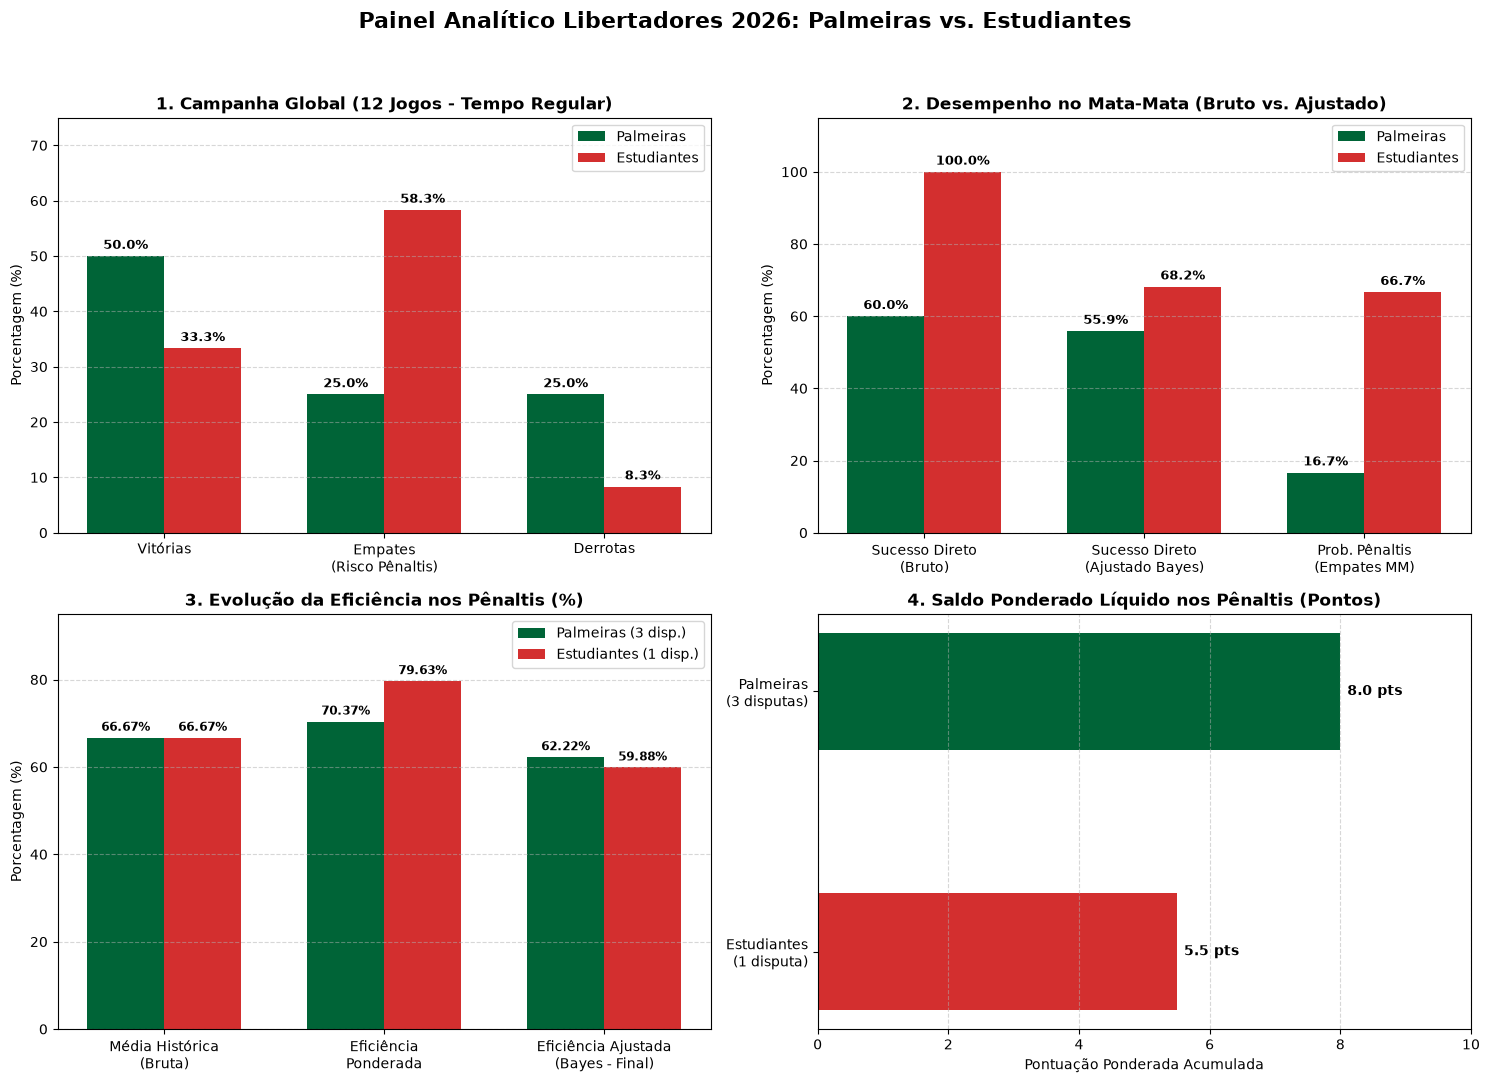

In [37]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Painel Analítico Libertadores 2026: Palmeiras vs. Estudiantes', fontsize=16, fontweight='bold', y=0.98)

cor_pal = '#006437' # Verde Palmeiras
cor_est = '#D32F2F' # Vermelho Estudiantes
w = 0.35

# --- GRÁFICO 1: Campanha Global (Tempo Regular) ---
ax1 = axs[0, 0]
cat_global = ['Vitórias', 'Empates\n(Risco Pênaltis)', 'Derrotas']
val_pal_global = [taxa_vitoria_global_palmeiras, taxa_empate_global_palmeiras, taxa_derrota_global_palmeiras]
val_est_global = [taxa_vitoria_global_estudiantes, taxa_empate_global_estudiantes, taxa_derrota_global_estudiantes]

x1 = np.arange(len(cat_global))
b1 = ax1.bar(x1 - w/2, val_pal_global, w, label='Palmeiras', color=cor_pal)
b2 = ax1.bar(x1 + w/2, val_est_global, w, label='Estudiantes', color=cor_est)

ax1.set_title('1. Campanha Global (12 Jogos - Tempo Regular)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Porcentagem (%)')
ax1.set_xticks(x1)
ax1.set_xticklabels(cat_global)
ax1.set_ylim(0, 75)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for barra in b1 + b2:
    h = barra.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(barra.get_x() + barra.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- GRÁFICO 2: Mata-Mata (Sucesso Direto Bruto vs. Ajustado & Risco Pênaltis) ---
ax2 = axs[0, 1]
cat_mm = ['Sucesso Direto\n(Bruto)', 'Sucesso Direto\n(Ajustado Bayes)', 'Prob. Pênaltis\n(Empates MM)']
val_pal_mm = [sucesso_direto_palmeiras, sucesso_direto_ajustado_palmeiras, probabilidade_penaltis_palmeiras]
val_est_mm = [sucesso_direto_estudiantes, sucesso_direto_ajustado_estudiantes, probabilidade_penaltis_estudiantes]

x2 = np.arange(len(cat_mm))
b3 = ax2.bar(x2 - w/2, val_pal_mm, w, label='Palmeiras', color=cor_pal)
b4 = ax2.bar(x2 + w/2, val_est_mm, w, label='Estudiantes', color=cor_est)

ax2.set_title('2. Desempenho no Mata-Mata (Bruto vs. Ajustado)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Porcentagem (%)')
ax2.set_xticks(x2)
ax2.set_xticklabels(cat_mm)
ax2.set_ylim(0, 115)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for barra in b3 + b4:
    h = barra.get_height()
    ax2.annotate(f'{h:.1f}%', xy=(barra.get_x() + barra.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- GRÁFICO 3: Evolução das Métricas de Pênaltis ---
ax3 = axs[1, 0]
cat_pen = ['Média Histórica\n(Bruta)', 'Eficiência\nPonderada', 'Eficiência Ajustada\n(Bayes - Final)']
val_pal_pen = [media_geral_penaltis_palmeiras, media_ponderada_penaltis_palmeiras, eficiencia_ajustada_palmeiras]
val_est_pen = [media_geral_penaltis_estudiantes, media_ponderada_penaltis_estudiantes, eficiencia_ajustada_estudiantes]

x3 = np.arange(len(cat_pen))
b5 = ax3.bar(x3 - w/2, val_pal_pen, w, label='Palmeiras (3 disp.)', color=cor_pal)
b6 = ax3.bar(x3 + w/2, val_est_pen, w, label='Estudiantes (1 disp.)', color=cor_est)

ax3.set_title('3. Evolução da Eficiência nos Pênaltis (%)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Porcentagem (%)')
ax3.set_xticks(x3)
ax3.set_xticklabels(cat_pen)
ax3.set_ylim(0, 95)
ax3.legend()
ax3.grid(axis='y', linestyle='--', alpha=0.5)

for barra in b5 + b6:
    h = barra.get_height()
    ax3.annotate(f'{h:.2f}%', xy=(barra.get_x() + barra.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# --- GRÁFICO 4: Saldo Ponderado Absoluto nos Pênaltis ---
ax4 = axs[1, 1]
times = ['Palmeiras\n(3 disputas)', 'Estudiantes\n(1 disputa)']
saldos = [saldo_palmeiras, saldo_estudiantes]
bars_saldo = ax4.barh(times, saldos, color=[cor_pal, cor_est], height=0.45)

ax4.set_title('4. Saldo Ponderado Líquido nos Pênaltis (Pontos)', fontsize=12, fontweight='bold')
ax4.set_xlabel('Pontuação Ponderada Acumulada')
ax4.set_xlim(0, 10)
ax4.grid(axis='x', linestyle='--', alpha=0.5)
ax4.invert_yaxis()

for barra in bars_saldo:
    w_bar = barra.get_width()
    ax4.annotate(f'{w_bar:.1f} pts', xy=(w_bar, barra.get_y() + barra.get_height()/2),
                 xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('assets/dashboard_completo_libertadores.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Validação Estatística: Teste Exato de Fisher ($\alpha = 0.05$)
Teste de hipótese em tabelas $2 \times 2$ para verificar se as diferenças observadas têm significância estatística ou se confirmam o equilíbrio entre os finalistas ($p \ge 0.05$).

In [38]:
from scipy.stats import fisher_exact

# 1. Teste na Campanha Global (12 jogos: Vitórias vs. Não-Vitórias [Empates + Derrotas])
nao_vitorias_pal = empates_totais_palmeiras + derrotas_totais_palmeiras
nao_vitorias_est = empates_totais_estudiantes + derrotas_totais_estudiantes

tabela_global = [
    [vitorias_totais_palmeiras, nao_vitorias_pal],
    [vitorias_totais_estudiantes, nao_vitorias_est]
]
or_global, p_global = fisher_exact(tabela_global)

# 2. Teste no Sucesso Direto do Mata-Mata (Vitórias vs. Derrotas, excluindo empates)
tabela_mata_mata = [
    [vitorias_palmeiras_mata_mata, derrotas_palmeiras_mata_mata],
    [vitorias_estudiantes_mata_mata, derrotas_estudiantes_mata_mata]
]
or_mm, p_mm = fisher_exact(tabela_mata_mata)

# 3. Teste nas Penalidades (Eventos Positivos vs. Eventos Negativos)
tabela_penaltis = [
    [positivos_palmeiras, negativos_palmeiras],
    [positivos_estudiantes, negativos_estudiantes]
]
or_pen, p_pen = fisher_exact(tabela_penaltis)

# Exibindo o Relatório Inferencial
resultados_testes = {
    "Campanha Global (12 jogos)": (or_global, p_global),
    "Sucesso Direto (Mata-Mata)": (or_mm, p_mm),
    "Eficiência nos Pênaltis": (or_pen, p_pen)
}

print("\n=== RESULTADOS DOS TESTES DE HIPÓTESE (FISHER) ===")
for cenario, (odds, p_val) in resultados_testes.items():
    significativo = "DIFERENÇA SIGNIFICATIVA (p < 0,05)" if p_val < 0.05 else "SEM EVIDÊNCIA DE DIFERENÇA (p ≥ 0,05)"
    print(f"{cenario}: Odds Ratio = {odds:.2f} | p-valor = {p_val:.4f} -> {significativo}")


=== RESULTADOS DOS TESTES DE HIPÓTESE (FISHER) ===
Campanha Global (12 jogos): Odds Ratio = 2.00 | p-valor = 0.6802 -> SEM EVIDÊNCIA DE DIFERENÇA (p ≥ 0,05)
Sucesso Direto (Mata-Mata): Odds Ratio = 0.00 | p-valor = 1.0000 -> SEM EVIDÊNCIA DE DIFERENÇA (p ≥ 0,05)
Eficiência nos Pênaltis: Odds Ratio = 1.00 | p-valor = 1.0000 -> SEM EVIDÊNCIA DE DIFERENÇA (p ≥ 0,05)


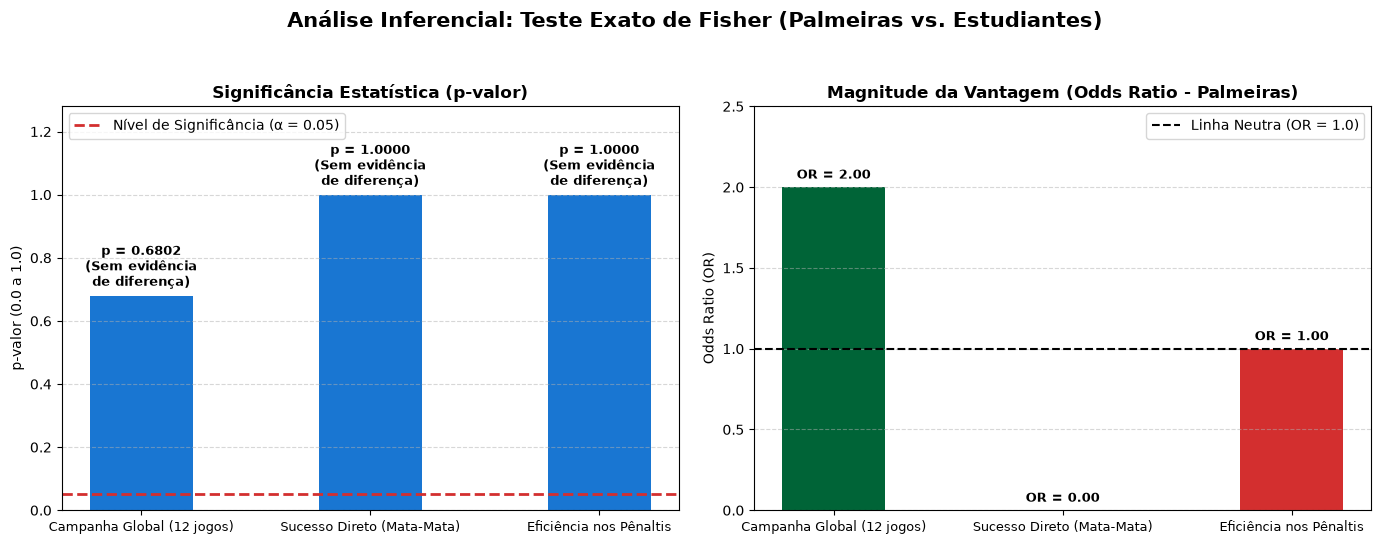

In [39]:
import matplotlib.pyplot as plt

# Extraindo os dados diretamente do dicionário resultados_testes para listas
cenarios = list(resultados_testes.keys())
p_valores = [valores[1] for valores in resultados_testes.values()]
odds_ratios = [valores[0] for valores in resultados_testes.values()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle('Análise Inferencial: Teste Exato de Fisher (Palmeiras vs. Estudiantes)', fontsize=15, fontweight='bold')

# --- GRÁFICO 1: p-valores vs. Linha de Significância (alpha = 0.05) ---
cores_p = ['#1976D2' if p >= 0.05 else '#D32F2F' for p in p_valores]
bars1 = ax1.bar(cenarios, p_valores, color=cores_p, width=0.45)
ax1.axhline(0.05, color='#D32F2F', linestyle='--', linewidth=2, label='Nível de Significância (α = 0.05)')

ax1.set_title('Significância Estatística (p-valor)', fontsize=12, fontweight='bold')
ax1.set_ylabel('p-valor (0.0 a 1.0)')
ax1.set_ylim(0, 1.28)
ax1.tick_params(axis='x', labelsize=9)
ax1.legend(loc='upper left')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars1:
    h = bar.get_height()
    status = 'Sem evidência\nde diferença' if h >= 0.05 else 'Significativo'
    ax1.annotate(f'p = {h:.4f}\n({status})', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- GRÁFICO 2: Razão de Chances (Odds Ratio) ---
cores_or = ['#006437' if o > 1 else ('#757575' if o == 0 else '#D32F2F') for o in odds_ratios]
bars2 = ax2.bar(cenarios, odds_ratios, color=cores_or, width=0.45)
ax2.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='Linha Neutra (OR = 1.0)')

ax2.set_title('Magnitude da Vantagem (Odds Ratio - Palmeiras)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Odds Ratio (OR)')
ax2.set_ylim(0, 2.5)
ax2.tick_params(axis='x', labelsize=9)
ax2.legend(loc='upper right')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f'OR = {h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('assets/grafico_fisher_inferencial.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Probabilidade Final de Título (Palmeiras vs. Estudiantes)
Representação visual do veredito analítico final após o cruzamento entre tempo normal e disputas de pênaltis.

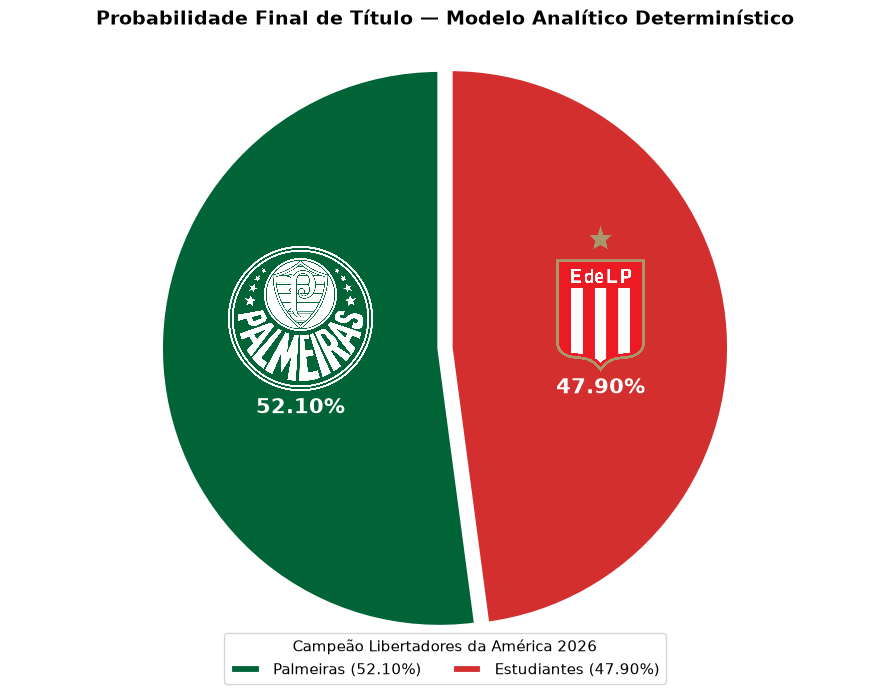

In [40]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as patches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# Função de segurança caso os arquivos .png ainda não estejam na pasta
def carregar_ou_criar_escudo(caminho_arquivo, clube):
    if os.path.exists(caminho_arquivo):
        return mpimg.imread(caminho_arquivo), True
    
# Carregando as imagens dos escudos
img_pal, usando_png_pal = carregar_ou_criar_escudo('assets/escudo_palmeiras.png', 'palmeiras')
img_est, usando_png_est = carregar_ou_criar_escudo('assets/escudo_estudiantes.png', 'estudiantes')

# Dados finais do Modelo Analítico Determinístico
valores = [prob_titulo_pal, prob_titulo_est]
cores = ['#006437', '#D32F2F']  # Verde Palmeiras e Vermelho Estudiantes
explode = (0.04, 0.0)          # Leve destaque para o favorito

fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor('white')

wedges, _ = ax.pie(
    valores,
    labels=None,
    startangle=90,
    colors=cores,
    explode=explode,
    wedgeprops={'edgecolor': 'white', 'linewidth': 3}
)

# Inserindo o escudo + porcentagem centralizados em cada fatia
imagens = [(img_pal, usando_png_pal), (img_est, usando_png_est)]

for wedge, (img, eh_png), pct in zip(wedges, imagens, valores):
    ang = (wedge.theta2 + wedge.theta1) / 2.0
    rad = np.deg2rad(ang)
    
    x_centro = 0.54 * np.cos(rad)
    y_centro = 0.54 * np.sin(rad)
    
    # Ajuste o valor de zoom (ex: 0.12 a 0.25) se o PNG baixado for muito grande ou pequeno
    fator_zoom = 0.07 if eh_png else 0.28
    imagebox = OffsetImage(img, zoom=fator_zoom)
    ab = AnnotationBbox(imagebox, (x_centro, y_centro + 0.14), frameon=False)
    ax.add_artist(ab)
    
    ax.text(
        x_centro, y_centro - 0.18,
        f'{pct:.2f}%',
        color='white',
        fontsize=15,
        fontweight='bold',
        ha='center',
        va='center'
    )

ax.legend(
    wedges,
    [f'Palmeiras ({prob_titulo_pal:.2f}%)', f'Estudiantes ({prob_titulo_est:.2f}%)'],
    title='Campeão Libertadores da América 2026',
    title_fontsize=11,
    fontsize=11,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.06),
    ncol=2,
    frameon=True
)

ax.set_title('Probabilidade Final de Título — Modelo Analítico Determinístico', fontsize=14, fontweight='bold', pad=12)
ax.axis('equal')

plt.tight_layout()
plt.savefig('grafico_pizza_campeao.png', dpi=300, bbox_inches='tight')
plt.savefig('assets/grafico_pizza_campeao.png', dpi=300, bbox_inches='tight')
plt.show()